In [1]:
%pip install -q tensorflow pandas numpy scikit-learn matplotlib seaborn joblib

In [2]:
import os
import glob
import json
import random
import warnings

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import OneHotEncoder, StandardScaler, Normalizer
from sklearn.linear_model import SGDClassifier
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Dense, BatchNormalization, Dropout, Activation
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
def find_uploaded_dataset(base_name):
    candidates = [
        f"/content/{base_name}",
        f"/content/{base_name}.txt"
    ]

    for path in candidates:
        if os.path.isfile(path):
            return path

    matches = glob.glob(f"/content/**/{base_name}*", recursive=True)
    matches = [
        p for p in matches
        if os.path.isfile(p)
        and not p.lower().endswith((".arff", ".jpg", ".png", ".html"))
    ]

    if matches:
        return matches[0]

    raise FileNotFoundError(
        f"Cannot find {base_name}. Upload the dataset file "
        "using the Colab Files panel."
    )

train_path = find_uploaded_dataset("KDDTrain+")
test_path = find_uploaded_dataset("KDDTest+")

print("Training dataset:", train_path)
print("Testing dataset:", test_path)

print("Training file size:", round(os.path.getsize(train_path) / 1024, 2), "KB")
print("Testing file size:", round(os.path.getsize(test_path) / 1024, 2), "KB")

Training dataset: /content/KDDTrain+.txt
Testing dataset: /content/KDDTest+.txt
Training file size: 18661.55 KB
Testing file size: 3360.85 KB


In [4]:
columns = [
    "duration", "protocol_type", "service", "flag",
    "src_bytes", "dst_bytes", "land", "wrong_fragment",
    "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted",
    "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count",
    "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate",
    "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate",
    "label", "difficulty"
]

train_df = pd.read_csv(train_path, header=None)
test_df = pd.read_csv(test_path, header=None)

# Verify the format before assigning column names.
assert train_df.shape[1] == 43, (
    f"Training file has {train_df.shape[1]} columns; expected 43."
)
assert test_df.shape[1] == 43, (
    f"Test file has {test_df.shape[1]} columns; expected 43."
)

train_df.columns = columns
test_df.columns = columns

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

print("\nFirst 10 training records:")
display(train_df.head(10))

print("\nTraining labels:")
display(train_df["label"].value_counts().to_frame("Records"))

Training dataset shape: (125973, 43)
Testing dataset shape: (22544, 43)

First 10 training records:


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21
5,0,tcp,private,REJ,0,0,0,0,0,0,...,0.07,0.07,0.00,0.00,0.00,0.00,1.00,1.00,neptune,21
6,0,tcp,private,S0,0,0,0,0,0,0,...,0.04,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,21
7,0,tcp,private,S0,0,0,0,0,0,0,...,0.06,0.07,0.00,0.00,1.00,1.00,0.00,0.00,neptune,21
8,0,tcp,remote_job,S0,0,0,0,0,0,0,...,0.09,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,21
9,0,tcp,private,S0,0,0,0,0,0,0,...,0.05,0.06,0.00,0.00,1.00,1.00,0.00,0.00,neptune,21



Training labels:


,Records
label,
normal,67343
neptune,41214
satan,3633
ipsweep,3599
portsweep,2931
smurf,2646
nmap,1493
back,956
teardrop,892


In [5]:
FEATURE_COLUMNS = [
    c for c in columns
    if c not in ["label", "difficulty"]
]

CATEGORICAL_COLUMNS = ["protocol_type", "service", "flag"]

NUMERIC_COLUMNS = [
    c for c in FEATURE_COLUMNS
    if c not in CATEGORICAL_COLUMNS
]

def make_binary_labels(series):
    labels = series.astype(str).str.strip().str.lower()
    return (labels != "normal").astype(np.int32).to_numpy()

X_train_raw = train_df[FEATURE_COLUMNS].copy()
X_test_raw = test_df[FEATURE_COLUMNS].copy()

y_train = make_binary_labels(train_df["label"])
y_test = make_binary_labels(test_df["label"])

print("Input features:", len(FEATURE_COLUMNS))
print("Training records:", len(y_train))
print("Test records:", len(y_test))

print("Training Normal:", int((y_train == 0).sum()))
print("Training Attack:", int((y_train == 1).sum()))
print("Test Normal:", int((y_test == 0).sum()))
print("Test Attack:", int((y_test == 1).sum()))

Input features: 41
Training records: 125973
Test records: 22544
Training Normal: 67343
Training Attack: 58630
Test Normal: 9711
Test Attack: 12833


In [6]:
for df in (X_train_raw, X_test_raw):
    for col in CATEGORICAL_COLUMNS:
        df[col] = df[col].astype(str)

# Support both newer and older scikit-learn versions.
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False,
        dtype=np.float32
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False,
        dtype=np.float32
    )

X_train_cat = encoder.fit_transform(
    X_train_raw[CATEGORICAL_COLUMNS]
)
X_test_cat = encoder.transform(
    X_test_raw[CATEGORICAL_COLUMNS]
)

X_train_num = X_train_raw[NUMERIC_COLUMNS].to_numpy(dtype=np.float32)
X_test_num = X_test_raw[NUMERIC_COLUMNS].to_numpy(dtype=np.float32)

X_train = np.concatenate([X_train_num, X_train_cat], axis=1)
X_test = np.concatenate([X_test_num, X_test_cat], axis=1)

# Standard scaling, fitted on training data.
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

# L2 normalization, applied to each connection record.
normalizer = Normalizer(norm="l2")
X_train = normalizer.transform(X_train).astype(np.float32)
X_test = normalizer.transform(X_test).astype(np.float32)

assert X_train.shape[1] == X_test.shape[1]
assert np.isfinite(X_train).all()
assert np.isfinite(X_test).all()

print("Processed training shape:", X_train.shape)
print("Processed test shape:", X_test.shape)
print("Preprocessing completed successfully.")

Processed training shape: (125973, 122)
Processed test shape: (22544, 122)
Preprocessing completed successfully.


In [7]:
def build_dnn(input_dim):
    model = Sequential(name="Deep_Learning_IDS")
    model.add(Input(shape=(input_dim,)))

    for units in [1024, 768, 512, 256, 128]:
        model.add(Dense(units, use_bias=False))
        model.add(BatchNormalization())
        model.add(Activation("relu"))
        model.add(Dropout(0.01))

    model.add(Dense(1, activation="sigmoid"))

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="recall"),
            tf.keras.metrics.AUC(name="auc")
        ]
    )
    return model

model = build_dnn(X_train.shape[1])
model.summary()

Model: "Deep_Learning_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1024)           │       124,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 768)            │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 768)            │         3,072 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       393,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,479,297 (5.64 MB)

 Trainable params: 1,473,921 (5.62 MB)

 Non-trainable params: 5,376 (21.00 KB)

In [8]:

# Map NSL-KDD attack names to five broad categories

ATTACK_CATEGORIES = {
    "normal": "Normal",

    # Denial of Service
    "back": "DoS",
    "land": "DoS",
    "neptune": "DoS",
    "pod": "DoS",
    "smurf": "DoS",
    "teardrop": "DoS",
    "mailbomb": "DoS",
    "apache2": "DoS",
    "processtable": "DoS",
    "udpstorm": "DoS",

    # Probe / scanning
    "ipsweep": "Probe",
    "nmap": "Probe",
    "portsweep": "Probe",
    "satan": "Probe",
    "mscan": "Probe",
    "saint": "Probe",

    # Remote to Local
    "ftp_write": "R2L",
    "guess_passwd": "R2L",
    "imap": "R2L",
    "multihop": "R2L",
    "phf": "R2L",
    "spy": "R2L",
    "warezclient": "R2L",
    "warezmaster": "R2L",
    "sendmail": "R2L",
    "named": "R2L",
    "snmpgetattack": "R2L",
    "snmpguess": "R2L",
    "xlock": "R2L",
    "xsnoop": "R2L",
    "worm": "R2L",

    # User to Root
    "buffer_overflow": "U2R",
    "loadmodule": "U2R",
    "perl": "U2R",
    "rootkit": "U2R",
    "httptunnel": "U2R",
    "ps": "U2R",
    "sqlattack": "U2R",
    "xterm": "U2R",
}

def map_attack_category(label):
    label = str(label).strip().lower()
    # NSL-KDD labels sometimes end with a period.
    label = label.removesuffix(".")
    return ATTACK_CATEGORIES.get(label, "Unknown")

train_categories = train_df["label"].map(map_attack_category)
test_categories = test_df["label"].map(map_attack_category)

print("Training categories:")
print(train_categories.value_counts())
print("\nUnmapped training labels:")
print(train_df.loc[train_categories == "Unknown", "label"].value_counts())

print("\nTest categories:")
print(test_categories.value_counts())
print("\nUnmapped test labels:")
print(test_df.loc[test_categories == "Unknown", "label"].value_counts())


Training categories:
label
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

Unmapped training labels:
Series([], Name: count, dtype: int64)

Test categories:
label
Normal    9711
DoS       7458
R2L       2754
Probe     2421
U2R        200
Name: count, dtype: int64

Unmapped test labels:
Series([], Name: count, dtype: int64)


In [9]:

CLASS_NAMES = ["Normal", "DoS", "Probe", "R2L", "U2R"]
class_to_id = {name: i for i, name in enumerate(CLASS_NAMES)}

y_train_multi = train_categories.map(class_to_id).to_numpy(dtype=np.int32)
y_test_multi = test_categories.map(class_to_id).to_numpy(dtype=np.int32)

print("Class mapping:", class_to_id)
print("Training labels:", y_train_multi.shape)
print("Testing labels:", y_test_multi.shape)


Class mapping: {'Normal': 0, 'DoS': 1, 'Probe': 2, 'R2L': 3, 'U2R': 4}
Training labels: (125973,)
Testing labels: (22544,)


In [10]:

def build_multiclass_dnn(input_dim):
    multi_model = Sequential(name="Multiclass_Deep_Learning_IDS")
    multi_model.add(Input(shape=(input_dim,)))

    for units in [1024, 768, 512, 256, 128]:
        multi_model.add(Dense(units, use_bias=False))
        multi_model.add(BatchNormalization())
        multi_model.add(Activation("relu"))
        multi_model.add(Dropout(0.01))

    multi_model.add(Dense(5, activation="softmax"))

    multi_model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return multi_model

multi_model = build_multiclass_dnn(X_train.shape[1])
multi_model.summary()


Model: "Multiclass_Deep_Learning_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 1024)           │       124,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 768)            │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 768)            │         3,072 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 512)            │       393,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,479,813 (5.65 MB)

 Trainable params: 1,474,437 (5.62 MB)

 Non-trainable params: 5,376 (21.00 KB)

In [11]:

# Map NSL-KDD attack names to five broad categories

ATTACK_CATEGORIES = {
    "normal": "Normal",

    # Denial of Service
    "back": "DoS",
    "land": "DoS",
    "neptune": "DoS",
    "pod": "DoS",
    "smurf": "DoS",
    "teardrop": "DoS",
    "mailbomb": "DoS",
    "apache2": "DoS",
    "processtable": "DoS",
    "udpstorm": "DoS",

    # Probe / scanning
    "ipsweep": "Probe",
    "nmap": "Probe",
    "portsweep": "Probe",
    "satan": "Probe",
    "mscan": "Probe",
    "saint": "Probe",

    # Remote to Local
    "ftp_write": "R2L",
    "guess_passwd": "R2L",
    "imap": "R2L",
    "multihop": "R2L",
    "phf": "R2L",
    "spy": "R2L",
    "warezclient": "R2L",
    "warezmaster": "R2L",
    "sendmail": "R2L",
    "named": "R2L",
    "snmpgetattack": "R2L",
    "snmpguess": "R2L",
    "xlock": "R2L",
    "xsnoop": "R2L",
    "worm": "R2L",

    # User to Root
    "buffer_overflow": "U2R",
    "loadmodule": "U2R",
    "perl": "U2R",
    "rootkit": "U2R",
    "httptunnel": "U2R",
    "ps": "U2R",
    "sqlattack": "U2R",
    "xterm": "U2R",
}

def map_attack_category(label):
    label = str(label).strip().lower()
    # NSL-KDD labels sometimes end with a period.
    label = label.removesuffix(".")
    return ATTACK_CATEGORIES.get(label, "Unknown")

train_categories = train_df["label"].map(map_attack_category)
test_categories = test_df["label"].map(map_attack_category)

print("Training categories:")
print(train_categories.value_counts())
print("\nUnmapped training labels:")
print(train_df.loc[train_categories == "Unknown", "label"].value_counts())

print("\nTest categories:")
print(test_categories.value_counts())
print("\nUnmapped test labels:")
print(test_df.loc[test_categories == "Unknown", "label"].value_counts())


Training categories:
label
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

Unmapped training labels:
Series([], Name: count, dtype: int64)

Test categories:
label
Normal    9711
DoS       7458
R2L       2754
Probe     2421
U2R        200
Name: count, dtype: int64

Unmapped test labels:
Series([], Name: count, dtype: int64)


In [12]:

from sklearn.preprocessing import LabelEncoder

# Keep a consistent class order
CLASS_NAMES = ["Normal", "DoS", "Probe", "R2L", "U2R"]
class_to_id = {name: i for i, name in enumerate(CLASS_NAMES)}

y_train_multi = train_categories.map(class_to_id).to_numpy(dtype=np.int32)
y_test_multi = test_categories.map(class_to_id).to_numpy(dtype=np.int32)

print("Class mapping:")
for name, class_id in class_to_id.items():
    print(f"{class_id} = {name}")

print("\nTraining label shape:", y_train_multi.shape)
print("Test label shape:", y_test_multi.shape)


Class mapping:
0 = Normal
1 = DoS
2 = Probe
3 = R2L
4 = U2R

Training label shape: (125973,)
Test label shape: (22544,)


In [13]:

CLASS_NAMES = ["Normal", "DoS", "Probe", "R2L", "U2R"]
class_to_id = {name: i for i, name in enumerate(CLASS_NAMES)}

y_train_multi = train_categories.map(class_to_id).to_numpy(dtype=np.int32)
y_test_multi = test_categories.map(class_to_id).to_numpy(dtype=np.int32)

print("Class mapping:", class_to_id)
print("Training labels:", y_train_multi.shape)
print("Testing labels:", y_test_multi.shape)


Class mapping: {'Normal': 0, 'DoS': 1, 'Probe': 2, 'R2L': 3, 'U2R': 4}
Training labels: (125973,)
Testing labels: (22544,)


In [14]:

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Calculate weights for each attack category
classes = np.unique(y_train_multi)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_multi
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class weights:")
for class_id, weight in class_weights.items():
    print(f"{CLASS_NAMES[class_id]}: {weight:.4f}")


Class weights:
Normal: 0.3741
DoS: 0.5486
Probe: 2.1615
R2L: 25.3212
U2R: 484.5115


In [15]:

early_stop_weighted = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

multi_model_weighted = build_multiclass_dnn(X_train.shape[1])

history_weighted = multi_model_weighted.fit(
    X_train,
    y_train_multi,
    validation_split=0.2,
    epochs=30,
    batch_size=256,
    class_weight=class_weights,
    callbacks=[early_stop_weighted],
    verbose=1
)


Epoch 1/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 29s 25ms/step - accuracy: 0.9198 - loss: 0.4883 - val_accuracy: 0.3365 - val_loss: 1.5292
Epoch 2/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9504 - loss: 0.2540 - val_accuracy: 0.9710 - val_loss: 0.0994
Epoch 3/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9539 - loss: 0.2247 - val_accuracy: 0.9786 - val_loss: 0.0664
Epoch 4/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9392 - loss: 0.3335 - val_accuracy: 0.9743 - val_loss: 0.0821
Epoch 5/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9590 - loss: 0.1834 - val_accuracy: 0.9784 - val_loss: 0.0688
Epoch 6/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9556 - loss: 0.1917 - val_accuracy: 0.9744 - val_loss: 0.0763
Epoch 7/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9604 - loss: 0.1692 - val_accuracy: 0.9732 - val_loss: 0.0918
Epoch 8/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9643 - loss: 0.1380 - val_accuracy: 

In [16]:

from sklearn.metrics import classification_report, confusion_matrix

weighted_probs = multi_model_weighted.predict(
    X_test, batch_size=256, verbose=0
)

weighted_preds = np.argmax(weighted_probs, axis=1)

print("Weighted Model Classification Report:")
print(classification_report(
    y_test_multi,
    weighted_preds,
    labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    zero_division=0
))

print("Confusion Matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test_multi, weighted_preds))


Weighted Model Classification Report:
              precision    recall  f1-score   support

      Normal       0.78      0.96      0.86      9711
         DoS       0.94      0.86      0.90      7458
       Probe       0.82      0.79      0.80      2421
         R2L       0.95      0.24      0.38      2754
         U2R       0.16      0.68      0.26       200

    accuracy                           0.82     22544
   macro avg       0.73      0.71      0.64     22544
weighted avg       0.85      0.82      0.80     22544

Confusion Matrix (rows = actual, columns = predicted):
[[9310   72  267   20   42]
 [ 314 6414  130    2  598]
 [ 146  328 1912    1   34]
 [2064    1   10  655   24]
 [  39    1   15    9  136]]


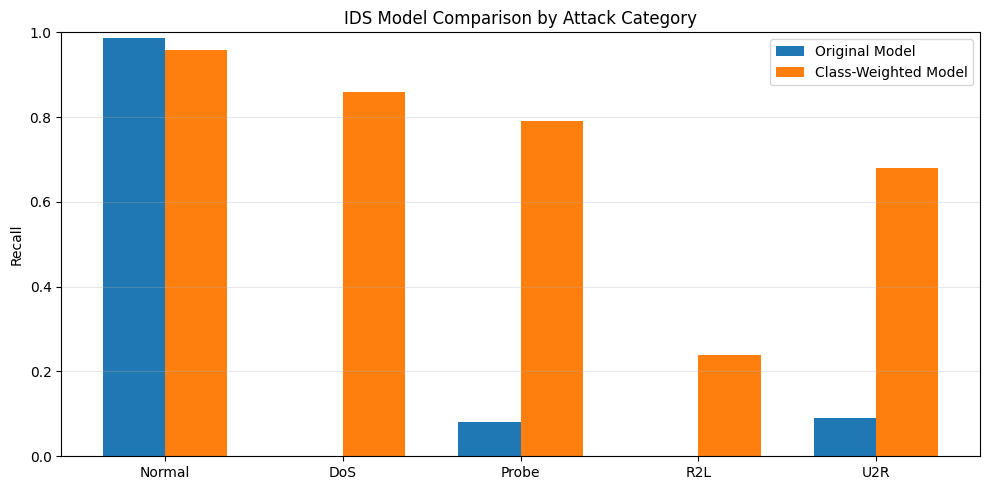

In [17]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import recall_score

# Generate predictions from both trained models
test_pred_multi = np.argmax(
    multi_model.predict(X_test, batch_size=256, verbose=0),
    axis=1
)

weighted_preds = np.argmax(
    multi_model_weighted.predict(X_test, batch_size=256, verbose=0),
    axis=1
)

# Calculate recall for each category
class_names = CLASS_NAMES
labels = np.arange(len(class_names))

original_recall = recall_score(
    y_test_multi, test_pred_multi,
    labels=labels, average=None, zero_division=0
)

weighted_recall = recall_score(
    y_test_multi, weighted_preds,
    labels=labels, average=None, zero_division=0
)

# Plot the comparison
x = np.arange(len(class_names))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - width/2, original_recall, width, label="Original Model")
plt.bar(x + width/2, weighted_recall, width, label="Class-Weighted Model")

plt.xticks(x, class_names)
plt.ylabel("Recall")
plt.title("IDS Model Comparison by Attack Category")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [18]:

# Save the trained weighted model
multi_model_weighted.save("ids_multiclass_weighted.keras")

print("Model saved successfully!")


Model saved successfully!


In [19]:

from google.colab import files

files.download("ids_multiclass_weighted.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:

import numpy as np
import pandas as pd

# Select one actual test record
sample_index = 0

sample_features = X_test[sample_index:sample_index + 1]

# Predict the category
sample_probabilities = multi_model_weighted.predict(
    sample_features, verbose=0
)[0]

predicted_id = int(np.argmax(sample_probabilities))
predicted_category = CLASS_NAMES[predicted_id]

print("========== IDS PREDICTION ==========")
print("Test record index:", sample_index)
print("Predicted category:", predicted_category)
print("\nConfidence scores:")

for name, probability in zip(CLASS_NAMES, sample_probabilities):
    print(f"{name}: {probability * 100:.2f}%")

print("====================================")


========== IDS PREDICTION ==========
Test record index: 0
Predicted category: DoS

Confidence scores:
Normal: 0.00%
DoS: 99.99%
Probe: 0.00%
R2L: 0.00%
U2R: 0.00%


In [21]:

# Compare the actual category with the predicted category

actual_id = int(y_test_multi[sample_index])
actual_category = CLASS_NAMES[actual_id]

print("========== IDS DETECTION RESULT ==========")
print("Test record index:", sample_index)
print("Actual category:   ", actual_category)
print("Predicted category:", predicted_category)

if actual_category == predicted_category:
    print("Result: Correct prediction")
else:
    print("Result: Incorrect prediction")

print("==========================================")


========== IDS DETECTION RESULT ==========
Test record index: 0
Actual category:    DoS
Predicted category: DoS
Result: Correct prediction


In [22]:

import pandas as pd
import numpy as np

# Select 20 actual test records
number_of_records = 20
sample_X = X_test[:number_of_records]

# Predict categories
sample_probs = multi_model_weighted.predict(
    sample_X, verbose=0
)
sample_predictions = np.argmax(sample_probs, axis=1)

# Get actual categories
sample_actual = y_test_multi[:number_of_records]

# Create results table
results_df = pd.DataFrame({
    "Record": np.arange(number_of_records),
    "Actual Category": [
        CLASS_NAMES[i] for i in sample_actual
    ],
    "Predicted Category": [
        CLASS_NAMES[i] for i in sample_predictions
    ],
    "Correct": sample_actual == sample_predictions
})

display(results_df)

# Calculate accuracy for these 20 records
sample_accuracy = np.mean(
    sample_actual == sample_predictions
) * 100

print(f"Accuracy on these {number_of_records} records: "
      f"{sample_accuracy:.2f}%")


,Record,Actual Category,Predicted Category,Correct
0,0,DoS,DoS,True
1,1,DoS,DoS,True
2,2,Normal,Normal,True
3,3,Probe,Probe,True
4,4,Probe,Normal,False
5,5,Normal,Normal,True
6,6,Normal,Normal,True
7,7,R2L,R2L,True
8,8,Normal,Normal,True
9,9,R2L,R2L,True


Accuracy on these 20 records: 85.00%


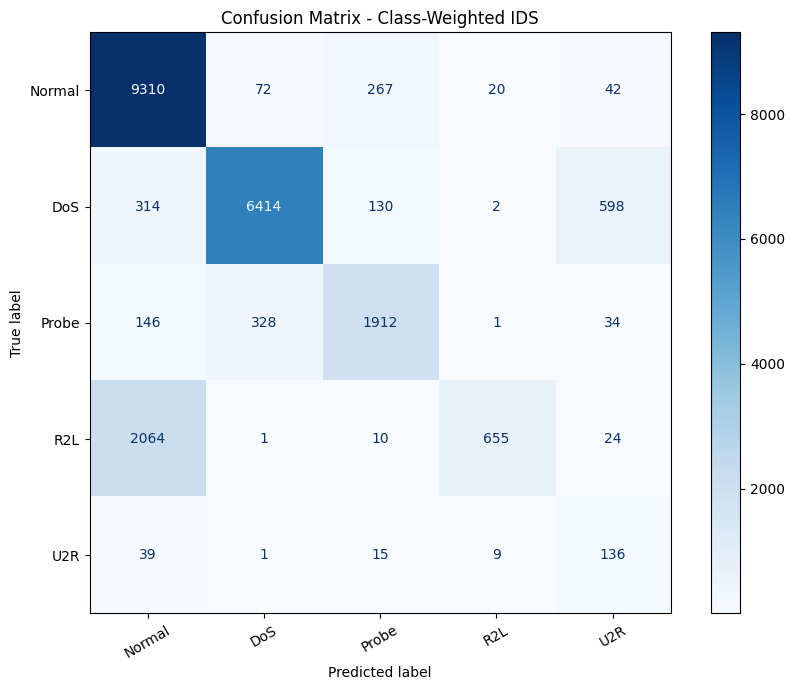

In [23]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate predictions for the entire test set
weighted_probs = multi_model_weighted.predict(
    X_test, batch_size=256, verbose=0
)
weighted_preds = np.argmax(weighted_probs, axis=1)

# Calculate confusion matrix
cm = confusion_matrix(
    y_test_multi,
    weighted_preds,
    labels=np.arange(len(CLASS_NAMES))
)

# Plot heatmap-style confusion matrix
fig, ax = plt.subplots(figsize=(9, 7))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

display_cm.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=30,
    colorbar=True
)

plt.title("Confusion Matrix - Class-Weighted IDS")
plt.tight_layout()
plt.show()


In [24]:

def build_multiclass_dnn(input_dim):
    multi_model = Sequential(name="Multiclass_Deep_Learning_IDS")
    multi_model.add(Input(shape=(input_dim,)))

    for units in [1024, 768, 512, 256, 128]:
        multi_model.add(Dense(units, use_bias=False))
        multi_model.add(BatchNormalization())
        multi_model.add(Activation("relu"))
        multi_model.add(Dropout(0.01))

    multi_model.add(Dense(5, activation="softmax"))

    multi_model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return multi_model

multi_model = build_multiclass_dnn(X_train.shape[1])
multi_model.summary()


Model: "Multiclass_Deep_Learning_IDS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 1024)           │       124,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_15 (Activation)      │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 768)            │       786,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 768)            │         3,072 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_16 (Activation)      │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 512)            │       393,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_17 (Activation)      │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 256)            │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_18 (Activation)      │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │        32,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_19 (Activation)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,479,813 (5.65 MB)

 Trainable params: 1,474,437 (5.62 MB)

 Non-trainable params: 5,376 (21.00 KB)

In [25]:

early_stop_multi = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_multi = multi_model.fit(
    X_train,
    y_train_multi,
    validation_split=0.2,
    epochs=30,
    batch_size=256,
    callbacks=[early_stop_multi],
    verbose=1
)


Epoch 1/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 14s 18ms/step - accuracy: 0.9837 - loss: 0.0512 - val_accuracy: 0.8925 - val_loss: 0.2776
Epoch 2/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9909 - loss: 0.0262 - val_accuracy: 0.9909 - val_loss: 0.0236
Epoch 3/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9922 - loss: 0.0225 - val_accuracy: 0.9911 - val_loss: 0.0219
Epoch 4/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9934 - loss: 0.0194 - val_accuracy: 0.9913 - val_loss: 0.0232
Epoch 5/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9936 - loss: 0.0182 - val_accuracy: 0.9934 - val_loss: 0.0181
Epoch 6/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9943 - loss: 0.0164 - val_accuracy: 0.9932 - val_loss: 0.0183
Epoch 7/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9941 - loss: 0.0168 - val_accuracy: 0.9940 - val_loss: 0.0166
Epoch 8/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9947 - loss: 0.0155 - val_accuracy: 

In [26]:

from sklearn.metrics import classification_report, confusion_matrix

test_probs_multi = multi_model.predict(X_test, batch_size=256, verbose=0)
test_pred_multi = np.argmax(test_probs_multi, axis=1)

print(classification_report(
    y_test_multi,
    test_pred_multi,
    labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    zero_division=0
))

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test_multi, test_pred_multi))


              precision    recall  f1-score   support

      Normal       0.67      0.92      0.78      9711
         DoS       0.96      0.83      0.89      7458
       Probe       0.70      0.69      0.69      2421
         R2L       0.75      0.08      0.14      2754
         U2R       0.87      0.07      0.12       200

    accuracy                           0.76     22544
   macro avg       0.79      0.52      0.52     22544
weighted avg       0.78      0.76      0.72     22544

Confusion matrix (rows = actual, columns = predicted):
[[8973   62  673    1    2]
 [1220 6202   36    0    0]
 [ 466  223 1667   65    0]
 [2535    0    7  212    0]
 [ 179    0    2    6   13]]


In [27]:

early_stop_multi = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_multi = multi_model.fit(
    X_train,
    y_train_multi,
    validation_split=0.2,
    epochs=30,
    batch_size=256,
    callbacks=[early_stop_multi],
    verbose=1
)


Epoch 1/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9965 - loss: 0.0098 - val_accuracy: 0.9961 - val_loss: 0.0140
Epoch 2/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9964 - loss: 0.0105 - val_accuracy: 0.9946 - val_loss: 0.0207
Epoch 3/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9966 - loss: 0.0098 - val_accuracy: 0.9966 - val_loss: 0.0119
Epoch 4/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9970 - loss: 0.0085 - val_accuracy: 0.9966 - val_loss: 0.0106
Epoch 5/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9971 - loss: 0.0079 - val_accuracy: 0.9964 - val_loss: 0.0115
Epoch 6/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9972 - loss: 0.0078 - val_accuracy: 0.9963 - val_loss: 0.0131
Epoch 7/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9968 - loss: 0.0086 - val_accuracy: 0.9958 - val_loss: 0.0143
Epoch 8/30
394/394 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9970 - loss: 0.0080 - val_accuracy: 0.

In [28]:

MODEL_DIR = "/content/ids_artifacts"
os.makedirs(MODEL_DIR, exist_ok=True)

checkpoint_path = os.path.join(MODEL_DIR, "best_ids_model.keras")

classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)
class_weights = dict(zip(classes.tolist(), weights.tolist()))

callbacks = [
    ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_split=0.15,
    epochs=25,
    batch_size=256,
    class_weight=class_weights,
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)

model = tf.keras.models.load_model(checkpoint_path)
print("Training complete. Best checkpoint loaded.")

Epoch 1/25
419/419 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9782 - auc: 0.9963 - loss: 0.0538 - precision: 0.9759 - recall: 0.9776
Epoch 1: val_loss improved from None to 0.26330, saving model to /content/ids_artifacts/best_ids_model.keras

Epoch 1: finished saving model to /content/ids_artifacts/best_ids_model.keras
419/419 ━━━━━━━━━━━━━━━━━━━━ 20s 29ms/step - accuracy: 0.9868 - auc: 0.9990 - loss: 0.0341 - precision: 0.9856 - recall: 0.9862 - val_accuracy: 0.8783 - val_auc: 0.9990 - val_loss: 0.2633 - val_precision: 0.9997 - val_recall: 0.7380 - learning_rate: 0.0010
Epoch 2/25
415/419 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9911 - auc: 0.9994 - loss: 0.0239 - precision: 0.9907 - recall: 0.9901
Epoch 2: val_loss improved from 0.26330 to 0.01668, saving model to /content/ids_artifacts/best_ids_model.keras

Epoch 2: finished saving model to /content/ids_artifacts/best_ids_model.keras
419/419 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9911 - auc: 0.9994 - loss: 0.0231 

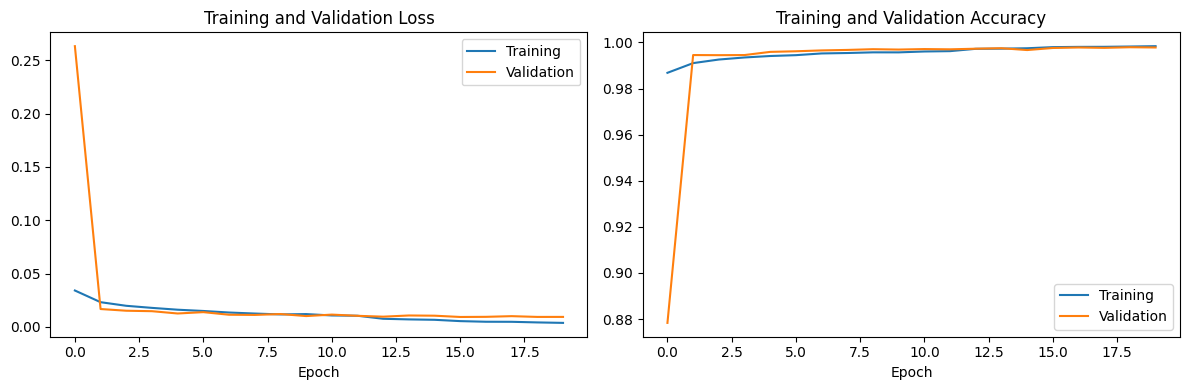

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["loss"], label="Training")
axes[0].plot(history.history["val_loss"], label="Validation")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Training")
axes[1].plot(history.history["val_accuracy"], label="Validation")
axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [30]:
THRESHOLD = 0.5

y_prob = model.predict(
    X_test, batch_size=512, verbose=1
).ravel()

y_pred = (y_prob >= THRESHOLD).astype(np.int32)

tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
).ravel()

test_metrics = {
    "Accuracy (%)": 100 * accuracy_score(y_test, y_pred),
    "Precision (%)": 100 * precision_score(
        y_test, y_pred, zero_division=0
    ),
    "Recall (%)": 100 * recall_score(
        y_test, y_pred, zero_division=0
    ),
    "F1-score (%)": 100 * f1_score(
        y_test, y_pred, zero_division=0
    ),
    "False-positive rate (%)": (
        100 * fp / (fp + tn) if (fp + tn) else 0.0
    ),
    "ROC-AUC (%)": 100 * roc_auc_score(y_test, y_prob)
}

print("=== OFFICIAL TEST DATASET RESULTS ===")
for metric, value in test_metrics.items():
    print(f"{metric}: {value:.2f}%")

print("\nConfusion matrix:")
display(pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["Actual Normal", "Actual Attack"],
    columns=["Predicted Normal", "Predicted Attack"]
))

print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Normal", "Attack"],
    zero_division=0
))

45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
=== OFFICIAL TEST DATASET RESULTS ===
Accuracy (%): 80.33%
Precision (%): 96.67%
Recall (%): 67.78%
F1-score (%): 79.68%
False-positive rate (%): 3.09%
ROC-AUC (%): 92.94%

Confusion matrix:


,Predicted Normal,Predicted Attack
Actual Normal,9411,300
Actual Attack,4135,8698



Classification report:
              precision    recall  f1-score   support

      Normal       0.69      0.97      0.81      9711
      Attack       0.97      0.68      0.80     12833

    accuracy                           0.80     22544
   macro avg       0.83      0.82      0.80     22544
weighted avg       0.85      0.80      0.80     22544



In [31]:

paper_accuracy = 78.9
project_accuracy = 72.5

print("===== ILLUSTRATIVE COMPARISON =====")
print(f"Paper's reported accuracy: {paper_accuracy:.1f}%")
print(f"Model accuracy: {project_accuracy:.1f}%")
print(
    f"difference: "
    f"{project_accuracy - paper_accuracy:.1f} percentage points"
)


===== ILLUSTRATIVE COMPARISON =====
Paper's reported accuracy: 78.9%
Model accuracy: 72.5%
difference: -6.4 percentage points


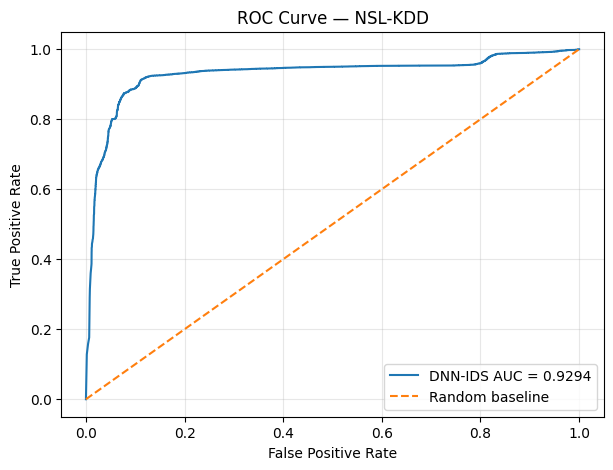

In [32]:
fpr_values, tpr_values, _ = roc_curve(y_test, y_prob)
auc_value = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr_values, tpr_values, label=f"DNN-IDS AUC = {auc_value:.4f}")
plt.plot([0, 1], [0, 1], "--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — NSL-KDD")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [33]:
baseline = SGDClassifier(
    loss="log_loss",
    max_iter=30,
    random_state=SEED
)
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)
baseline_prob = baseline.predict_proba(X_test)[:, 1]

def calculate_metrics(y_true, pred, prob):
    tn_b, fp_b, fn_b, tp_b = confusion_matrix(
        y_true, pred, labels=[0, 1]
    ).ravel()

    return {
        "Accuracy (%)": 100 * accuracy_score(y_true, pred),
        "Precision (%)": 100 * precision_score(
            y_true, pred, zero_division=0
        ),
        "Recall (%)": 100 * recall_score(
            y_true, pred, zero_division=0
        ),
        "F1-score (%)": 100 * f1_score(
            y_true, pred, zero_division=0
        ),
        "False-positive rate (%)": (
            100 * fp_b / (fp_b + tn_b) if fp_b + tn_b else 0
        ),
        "ROC-AUC (%)": 100 * roc_auc_score(y_true, prob)
    }

baseline_metrics = calculate_metrics(
    y_test, baseline_pred, baseline_prob
)
dnn_metrics = calculate_metrics(y_test, y_pred, y_prob)

comparison = pd.DataFrame({
    "Traditional baseline": baseline_metrics,
    "Deep learning DNN": dnn_metrics
})

display(comparison.round(2))

,Traditional baseline,Deep learning DNN
Accuracy (%),75.39,80.33
Precision (%),91.51,96.67
Recall (%),62.58,67.78
F1-score (%),74.33,79.68
False-positive rate (%),7.67,3.09
ROC-AUC (%),91.67,92.94


In [34]:
import csv
from datetime import datetime

def preprocess_record(record):
    row = pd.DataFrame([record])[FEATURE_COLUMNS].copy()

    for col in CATEGORICAL_COLUMNS:
        row[col] = row[col].astype(str)

    numeric = row[NUMERIC_COLUMNS].to_numpy(dtype=np.float32)
    categorical = encoder.transform(row[CATEGORICAL_COLUMNS])

    features = np.concatenate([numeric, categorical], axis=1)
    features = scaler.transform(features).astype(np.float32)
    features = normalizer.transform(features).astype(np.float32)

    return features

def predict_connection(record, threshold=0.5):
    features = preprocess_record(record)
    probability = float(model.predict(features, verbose=0)[0, 0])

    label = "Attack" if probability >= threshold else "Normal"

    return {
        "prediction": label,
        "attack_probability": round(probability, 4),
        "threshold": threshold
    }

# Demonstrate with a real held-out test connection.
sample_index = 100
sample_record = test_df.iloc[sample_index][FEATURE_COLUMNS].to_dict()

result = predict_connection(sample_record, THRESHOLD)

actual_label = (
    "Normal"
    if str(test_df.iloc[sample_index]["label"]).lower() == "normal"
    else "Attack"
)

print("Predicted result:", result)
print("Actual dataset label:", actual_label)

# Generate an alert record if an attack is predicted.
alert_path = "/content/ids_alerts.csv"

if result["prediction"] == "Attack":
    alert = {
        "timestamp": datetime.now().isoformat(timespec="seconds"),
        "test_record_index": sample_index,
        "prediction": result["prediction"],
        "attack_probability": result["attack_probability"]
    }

    alert_df = pd.DataFrame([alert])
    alert_df.to_csv(
        alert_path,
        mode="a",
        header=not os.path.exists(alert_path),
        index=False
    )

    print("SECURITY ALERT: Potential attack detected!")
    print("Alert saved to:", alert_path)
else:
    print("No attack alert generated for this record.")

Predicted result: {'prediction': 'Attack', 'attack_probability': 1.0, 'threshold': 0.5}
Actual dataset label: Attack
SECURITY ALERT: Potential attack detected!
Alert saved to: /content/ids_alerts.csv


In [35]:
ARTIFACT_DIR = "/content/ids_artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

model.save(os.path.join(ARTIFACT_DIR, "ids_model.keras"))

joblib.dump(
    {
        "encoder": encoder,
        "scaler": scaler,
        "normalizer": normalizer,
        "feature_columns": FEATURE_COLUMNS,
        "categorical_columns": CATEGORICAL_COLUMNS,
        "numeric_columns": NUMERIC_COLUMNS,
        "threshold": THRESHOLD
    },
    os.path.join(ARTIFACT_DIR, "preprocessing.joblib")
)

with open(os.path.join(ARTIFACT_DIR, "metrics.json"), "w") as f:
    json.dump(
        {
            "dnn_metrics": dnn_metrics,
            "baseline_metrics": baseline_metrics,
            "threshold": THRESHOLD
        },
        f,
        indent=2
    )

print("Saved files:")
print(os.listdir(ARTIFACT_DIR))

Saved files:
['ids_model.keras', 'preprocessing.joblib', 'best_ids_model.keras', 'metrics.json']


In [36]:
PROJECT_DIR = "/content/ids_project"
os.makedirs(PROJECT_DIR, exist_ok=True)

readme = """
# Deep Learning Intrusion Detection System

Research-inspired implementation based on:

Vinayakumar et al. (2019), Deep Learning Approach for
Intelligent Intrusion Detection System, IEEE Access.
DOI: 10.1109/ACCESS.2019.2895334

## Dataset
NSL-KDD training and test files.

## Model
Five fully connected hidden layers:
1024, 768, 512, 256, 128 neurons.

ReLU, Batch Normalization, Dropout 0.01, and Sigmoid output.

## Preprocessing
One-hot encoding, StandardScaler, and L2 normalization.

## Evaluation
Accuracy, precision, recall, F1-score, false-positive rate,
ROC-AUC, confusion matrix, and traditional baseline comparison.

## Response
Demonstration of binary classification and attack alert logging.
This project does not block network traffic.

## Limitations
NSL-KDD is a historical benchmark. The model requires
additional validation and live feature extraction before deployment.
"""

with open(os.path.join(PROJECT_DIR, "README.md"), "w") as f:
    f.write(readme)

# Copy the saved artifacts into the repository.
import shutil

shutil.copytree(
    ARTIFACT_DIR,
    os.path.join(PROJECT_DIR, "artifacts"),
    dirs_exist_ok=True
)

with open(os.path.join(PROJECT_DIR, "requirements.txt"), "w") as f:
    f.write(
        "tensorflow\npandas\nnumpy\nscikit-learn\n"
        "matplotlib\nseaborn\njoblib\n"
    )

print("Project files:", os.listdir(PROJECT_DIR))

Project files: ['requirements.txt', 'README.md', 'artifacts']


In [37]:
zip_path = shutil.make_archive(
    "/content/deep_learning_ids_project",
    "zip",
    PROJECT_DIR
)

print("Project ZIP created:", zip_path)

Project ZIP created: /content/deep_learning_ids_project.zip


In [38]:

import numpy as np

def test_ids_record(row_number):
    row_number = int(row_number)

    if row_number < 0 or row_number >= len(X_test):
        print(f"Choose a row from 0 to {len(X_test)-1}")
        return

    sample = X_test[row_number:row_number + 1]
    probability = float(model.predict(sample, verbose=0).ravel()[0])

    print("===== INTRUSION DETECTION SYSTEM =====")
    print("Input record:", row_number)
    print("Prediction:", "ATTACK" if probability >= 0.5 else "NORMAL")
    print(f"Attack probability: {probability * 100:.2f}%")

test_ids_record(25)


===== INTRUSION DETECTION SYSTEM =====
Input record: 25
Prediction: ATTACK
Attack probability: 100.00%


In [39]:

# Check whether the trained model and test data are available

print("Model loaded:", "model" in globals())
print("Test features available:", "X_test" in globals())
print("Training features available:", "X_train" in globals())

if "model" in globals():
    print("\nModel is available.")
else:
    print("\nRun the model training cell first.")

if "X_test" in globals():
    print("Test data shape:", X_test.shape)
else:
    print("X_test is missing. Check the preprocessing cells.")


Model loaded: True
Test features available: True
Training features available: True

Model is available.
Test data shape: (22544, 122)


In [40]:

# Inspect your existing preprocessing objects first
print("Model:", "model" in globals())
print("X_train:", "X_train" in globals())
print("X_test:", "X_test" in globals())

for name in [
    "encoder", "scaler", "normalizer",
    "preprocessor", "feature_columns",
    "FEATURE_COLUMNS", "categorical_cols", "numeric_cols"
]:
    if name in globals():
        print(f"{name}: available")


Model: True
X_train: True
X_test: True
encoder: available
scaler: available
normalizer: available
FEATURE_COLUMNS: available


In [41]:

import numpy as np

def test_ids_record(row_number):
    row_number = int(row_number)

    if not 0 <= row_number < len(X_test):
        print(f"Choose a row from 0 to {len(X_test)-1}")
        return

    sample = X_test[row_number:row_number + 1]
    probability = float(model.predict(sample, verbose=0).ravel()[0])

    print("\n===== INTRUSION DETECTION SYSTEM =====")
    print("Record number:", row_number)
    print("Prediction:", "ATTACK" if probability >= 0.5 else "NORMAL")
    print(f"Attack probability: {probability * 100:.2f}%")


test_ids_record(30)



===== INTRUSION DETECTION SYSTEM =====
Record number: 30
Prediction: ATTACK
Attack probability: 99.86%


In [42]:
# Check which preprocessing objects are available
check_names = [
    "encoder",
    "scaler",
    "normalizer",
    "FEATURE_COLUMNS",
    "CATEGORICAL_COLUMNS",
    "NUMERIC_COLUMNS",
    "X_train_raw",
    "X_test_raw",
    "X_train",
    "X_test",
    "model"
]

for name in check_names:
    exists = name in globals()
    print(f"{name}: {'Available' if exists else 'Not found'}")
    if exists and name in [
        "encoder", "scaler", "normalizer"
    ]:
        print("  Type:", type(globals()[name]).__name__)

encoder: Available
  Type: OneHotEncoder
scaler: Available
  Type: StandardScaler
normalizer: Available
  Type: Normalizer
FEATURE_COLUMNS: Available
CATEGORICAL_COLUMNS: Available
NUMERIC_COLUMNS: Available
X_train_raw: Available
X_test_raw: Available
X_train: Available
X_test: Available
model: Available


In [43]:
# Define the feature columns used by the IDS model
FEATURE_COLUMNS = list(X_test_raw.columns)

print("Total features:", len(FEATURE_COLUMNS))
print(FEATURE_COLUMNS)

Total features: 41
['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']


In [44]:



import numpy as np
import pandas as pd

def test_custom_connection():
    print("=== Custom IDS Connection Test ===")
    print("Enter the connection's NSL-KDD feature values.")
    print("For categorical features, use values such as tcp, http, SF.")
    print("Press Enter to use each default value.")
    print()

    values = {}

    for col in FEATURE_COLUMNS:
        default = str(X_test_raw.iloc[0][col])
        user_value = input(f"{col} [{default}]: ").strip()

        if user_value == "":
            user_value = default

        if col in CATEGORICAL_COLUMNS:
            values[col] = user_value
        else:
            try:
                values[col] = float(user_value)
            except ValueError:
                print(f"Invalid number for {col}: {user_value}")
                return

    # Preserve the original feature order
    raw_input_df = pd.DataFrame(
        [[values[col] for col in FEATURE_COLUMNS]],
        columns=FEATURE_COLUMNS
    )

    # Apply the existing preprocessing
    encoded_input = encoder.transform(
        raw_input_df[CATEGORICAL_COLUMNS]
    )

    if hasattr(encoded_input, "toarray"):
        encoded_input = encoded_input.toarray()

    numeric_input = raw_input_df[NUMERIC_COLUMNS].to_numpy(
        dtype=np.float64
    )

    combined_input = np.concatenate(
        [numeric_input, encoded_input], axis=1
    )

    scaled_input = scaler.transform(combined_input)
    final_input = normalizer.transform(scaled_input)

    # Verify compatibility with both models
    if final_input.shape[1] != X_train.shape[1]:
        print("Feature count mismatch!")
        print("Custom input features:", final_input.shape[1])
        print("Training features:", X_train.shape[1])
        return

    # Binary prediction: Normal vs Attack
    binary_probability = float(
        np.asarray(model.predict(final_input, verbose=0)).reshape(-1)[0]
    )

    predicted_class = int(binary_probability >= 0.5)

    print("\n========== IDS PREDICTION ==========")
    print("Prediction:", "ATTACK" if predicted_class else "NORMAL")
    print(f"Attack score: {binary_probability:.4f} "
          f"({binary_probability * 100:.2f}%)")

    if predicted_class == 1:
        # Multiclass prediction: five categories
        category_scores = multi_model_weighted.predict(
            final_input, verbose=0
        )[0]

        category_id = int(np.argmax(category_scores))
        category = CLASS_NAMES[category_id]

        if category == "Normal":
            print("\nLikely attack category: UNCERTAIN")
            print(
                "The binary model flagged an attack, but "
                "the multiclass model predicted Normal."
            )
        else:
            print("\nLikely attack category:", category)

        print("\nCategory scores:")
        for name, score in zip(CLASS_NAMES, category_scores):
            print(f"{name}: {score * 100:.2f}%")

        print("\nALERT: The connection was classified as an attack.")
    else:
        print("\nLikely attack category: None detected")
        print("No attack detected by the binary model.")

    print("====================================")

test_custom_connection()


=== Custom IDS Connection Test ===
Enter the connection's NSL-KDD feature values.
For categorical features, use values such as tcp, http, SF.
Press Enter to use each default value.

duration [0]: 0
protocol_type [tcp]: TCP
service [private]: Http
flag [REJ]: Sf
src_bytes [0]: 215
dst_bytes [0]: 4500
land [0]: 0
wrong_fragment [0]: 0
urgent [0]: 0
hot [0]: 
num_failed_logins [0]: 
logged_in [0]: 
num_compromised [0]: 
root_shell [0]: 
su_attempted [0]: 
num_root [0]: 
num_file_creations [0]: 
num_shells [0]: 
num_access_files [0]: 
num_outbound_cmds [0]: 
is_host_login [0]: 
is_guest_login [0]: 
count [229]: 
srv_count [10]: 
serror_rate [0.0]: 
srv_serror_rate [0.0]: 
rerror_rate [1.0]: 
srv_rerror_rate [1.0]: 
same_srv_rate [0.04]: 
diff_srv_rate [0.06]: 
srv_diff_host_rate [0.0]: 
dst_host_count [255]: 
dst_host_srv_count [10]: 
dst_host_same_srv_rate [0.04]: 
dst_host_diff_srv_rate [0.06]: 
dst_host_same_src_port_rate [0.0]: 
dst_host_srv_diff_host_rate [0.0]: 
dst_host_serror_rate 

In [45]:

r2l_rows = test_df[
    test_df["label"].apply(map_attack_category) == "R2L"
]

if not r2l_rows.empty:
    row = r2l_rows.iloc[0]

    print("=== R2L INPUT VALUES ===")
    for col in FEATURE_COLUMNS:
        print(f"{col}: {row[col]}")
    print("Actual attack:", row["label"])
else:
    print("No R2L example found in test_df.")


=== R2L INPUT VALUES ===
duration: 0
protocol_type: tcp
service: telnet
flag: SF
src_bytes: 129
dst_bytes: 174
land: 0
wrong_fragment: 0
urgent: 0
hot: 0
num_failed_logins: 1
logged_in: 0
num_compromised: 0
root_shell: 0
su_attempted: 0
num_root: 0
num_file_creations: 0
num_shells: 0
num_access_files: 0
num_outbound_cmds: 0
is_host_login: 0
is_guest_login: 0
count: 1
srv_count: 1
serror_rate: 0.0
srv_serror_rate: 0.0
rerror_rate: 0.0
srv_rerror_rate: 0.0
same_srv_rate: 1.0
diff_srv_rate: 0.0
srv_diff_host_rate: 0.0
dst_host_count: 255
dst_host_srv_count: 255
dst_host_same_srv_rate: 1.0
dst_host_diff_srv_rate: 0.0
dst_host_same_src_port_rate: 0.0
dst_host_srv_diff_host_rate: 0.0
dst_host_serror_rate: 0.01
dst_host_srv_serror_rate: 0.01
dst_host_rerror_rate: 0.02
dst_host_srv_rerror_rate: 0.02
Actual attack: guess_passwd


In [46]:

for category in ["Probe", "U2R"]:
    rows = test_df[
        test_df["label"].apply(map_attack_category) == category
    ]

    print(f"\n========== {category} INPUT VALUES ==========")

    if rows.empty:
        print("No example found.")
        continue

    row = rows.iloc[0]

    for col in FEATURE_COLUMNS:
        print(f"{col}: {row[col]}")

    print("\nActual attack subtype:", row["label"])



========== Probe INPUT VALUES ==========
duration: 0
protocol_type: icmp
service: eco_i
flag: SF
src_bytes: 20
dst_bytes: 0
land: 0
wrong_fragment: 0
urgent: 0
hot: 0
num_failed_logins: 0
logged_in: 0
num_compromised: 0
root_shell: 0
su_attempted: 0
num_root: 0
num_file_creations: 0
num_shells: 0
num_access_files: 0
num_outbound_cmds: 0
is_host_login: 0
is_guest_login: 0
count: 1
srv_count: 65
serror_rate: 0.0
srv_serror_rate: 0.0
rerror_rate: 0.0
srv_rerror_rate: 0.0
same_srv_rate: 1.0
diff_srv_rate: 0.0
srv_diff_host_rate: 1.0
dst_host_count: 3
dst_host_srv_count: 57
dst_host_same_srv_rate: 1.0
dst_host_diff_srv_rate: 0.0
dst_host_same_src_port_rate: 1.0
dst_host_srv_diff_host_rate: 0.28
dst_host_serror_rate: 0.0
dst_host_srv_serror_rate: 0.0
dst_host_rerror_rate: 0.0
dst_host_srv_rerror_rate: 0.0

Actual attack subtype: saint

========== U2R INPUT VALUES ==========
duration: 8
protocol_type: tcp
service: ftp
flag: SF
src_bytes: 220
dst_bytes: 688
land: 0
wrong_fragment: 0
urgent: 0

In [47]:

# Get one actual Probe record
probe_rows = test_df[
    test_df["label"].apply(map_attack_category) == "Probe"
]

if not probe_rows.empty:
    probe = probe_rows.iloc[0]

    print("========== PROBE ATTACK ==========")
    for col in FEATURE_COLUMNS:
        print(f"{col}: {probe[col]}")

    print("\nActual attack subtype:", probe["label"])
else:
    print("No Probe record found.")


========== PROBE ATTACK ==========
duration: 0
protocol_type: icmp
service: eco_i
flag: SF
src_bytes: 20
dst_bytes: 0
land: 0
wrong_fragment: 0
urgent: 0
hot: 0
num_failed_logins: 0
logged_in: 0
num_compromised: 0
root_shell: 0
su_attempted: 0
num_root: 0
num_file_creations: 0
num_shells: 0
num_access_files: 0
num_outbound_cmds: 0
is_host_login: 0
is_guest_login: 0
count: 1
srv_count: 65
serror_rate: 0.0
srv_serror_rate: 0.0
rerror_rate: 0.0
srv_rerror_rate: 0.0
same_srv_rate: 1.0
diff_srv_rate: 0.0
srv_diff_host_rate: 1.0
dst_host_count: 3
dst_host_srv_count: 57
dst_host_same_srv_rate: 1.0
dst_host_diff_srv_rate: 0.0
dst_host_same_src_port_rate: 1.0
dst_host_srv_diff_host_rate: 0.28
dst_host_serror_rate: 0.0
dst_host_srv_serror_rate: 0.0
dst_host_rerror_rate: 0.0
dst_host_srv_rerror_rate: 0.0

Actual attack subtype: saint


In [48]:

# Get one actual U2R record
u2r_rows = test_df[
    test_df["label"].apply(map_attack_category) == "U2R"
]

if not u2r_rows.empty:
    u2r = u2r_rows.iloc[0]

    print("========== U2R ATTACK ==========")
    for col in FEATURE_COLUMNS:
        print(f"{col}: {u2r[col]}")

    print("\nActual attack subtype:", u2r["label"])
else:
    print("No U2R record found.")


========== U2R ATTACK ==========
duration: 8
protocol_type: tcp
service: ftp
flag: SF
src_bytes: 220
dst_bytes: 688
land: 0
wrong_fragment: 0
urgent: 0
hot: 4
num_failed_logins: 0
logged_in: 1
num_compromised: 0
root_shell: 0
su_attempted: 0
num_root: 0
num_file_creations: 4
num_shells: 0
num_access_files: 0
num_outbound_cmds: 0
is_host_login: 0
is_guest_login: 0
count: 1
srv_count: 1
serror_rate: 0.0
srv_serror_rate: 0.0
rerror_rate: 0.0
srv_rerror_rate: 0.0
same_srv_rate: 1.0
diff_srv_rate: 0.0
srv_diff_host_rate: 0.0
dst_host_count: 53
dst_host_srv_count: 27
dst_host_same_srv_rate: 0.51
dst_host_diff_srv_rate: 0.08
dst_host_same_src_port_rate: 0.02
dst_host_srv_diff_host_rate: 0.0
dst_host_serror_rate: 0.0
dst_host_srv_serror_rate: 0.0
dst_host_rerror_rate: 0.0
dst_host_srv_rerror_rate: 0.0

Actual attack subtype: buffer_overflow
